# Seance 9 - Projet du groupe 3 : restauration collective

**Groupe 3 - cantine.** Ajouter les noms des membres et la date de soutenance avant le depot.

| Element | Valeur |
|---|---|
| Groupe | Groupe 3 - cantine |
| Membres | A completer |
| Sujet | Repas servis, regimes, statuts et couts par etablissement et famille de menu |
| Question | Quels etablissements et familles concentrent les repas consommes, les annulations et les repas non recuperes ? |
| Soutenance | A completer |

Presentation : 15 minutes, puis 10 minutes de questions.

## 1. Contexte et sources

Les donnees attribuees au groupe 3 portent sur les repas servis. La table des faits est reliee aux referentiels convives, menus et etablissements. Les statuts sont `consomme`, `annule` et `non_recupere`. Le jeu est synthetique et couvre 2023-2024.

Les indicateurs de consommation comptent uniquement les lignes au statut `consomme`. Les couts sont les valeurs declarees dans les evenements consommes ; elles ne sont pas multipliees par les portions, car la granularite du cout n'est pas documentee.

In [1]:
from pathlib import Path
import sys, time, importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
GROUP_DIR = ROOT / "data" / "groupe_03_cantine" / "groupe_03_cantine"
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "reports" / "figures"
ARTIFACTS_DIR = ROOT / "reports" / "artifacts"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
paths = {name: GROUP_DIR / f"{name}.csv" for name in ["repas_servis", "convives", "menus", "etablissements"]}
missing = [str(path) for path in paths.values() if not path.exists()]
if missing:
    raise FileNotFoundError("Fichiers sources manquants : " + ", ".join(missing))
print("Donnees groupe 3 - cantine :")
for name, path in paths.items():
    print(f"  {name:<15} {path.stat().st_size / 1024:,.1f} Ko")

Donnees groupe 3 - cantine :
  repas_servis    1,424.0 Ko
  convives        104.2 Ko
  menus           10.2 Ko
  etablissements  0.5 Ko


In [2]:
raw_meals = pd.read_csv(paths["repas_servis"])
raw_diners = pd.read_csv(paths["convives"])
raw_menus = pd.read_csv(paths["menus"])
raw_sites = pd.read_csv(paths["etablissements"])
for name, frame in [("Repas servis", raw_meals), ("Convives", raw_diners), ("Menus", raw_menus), ("Etablissements", raw_sites)]:
    print(f"{name}: {frame.shape[0]:,} lignes x {frame.shape[1]} colonnes; doublons stricts = {frame.duplicated().sum():,}")
display(raw_meals.head())

Repas servis: 18,683 lignes x 10 colonnes; doublons stricts = 220
Convives: 2,270 lignes x 5 colonnes; doublons stricts = 0
Menus: 180 lignes x 5 colonnes; doublons stricts = 0
Etablissements: 11 lignes x 5 colonnes; doublons stricts = 0


,id_repas_servi,date_evenement,id_convive,id_menu,id_etablissement,portions_servies,grammage_g,cout_revient_eur,regime,statut
0,RPS0013329,2024-10-02,CNV00604,MNU0017,ETB09,2,269.0,4.62,standard,consomme
1,RPS0000830,2024-01-05,CNV01613,MNU0025,ETB04,3,127.0,3.72,standard,consomme
2,RPS0001047,2024-01-18,CNV01665,MNU0140,ETB01,1,NaN,6.75,vegetarien,consomme
3,RPS0001466,2024-12-21,CNV01109,MNU0158,ETB05,1,151.0,2.17,standard,annule
4,RPS0002817,2023-10-14,CNV00127,MNU0148,ETB04,3,NaN,5.65,vegetarien,non_recupere


## 2. Diagnostic chiffre

On mesure separement les doublons exacts, les ids repetes, les dates manquantes, les quantites atypiques et la couverture des references. Un id repete n'est pas automatiquement une anomalie si les lignes divergent ; ici les lignes dupliquees strictement sont retirees.

In [3]:
def normalize_text(series):
    text = series.astype("string").str.strip().str.lower()
    text = text.str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("utf-8")
    return text.str.replace(r"\s+", " ", regex=True)

raw_id_counts = raw_meals["id_repas_servi"].value_counts(dropna=True)
reused_rows = int(raw_meals["id_repas_servi"].isin(raw_id_counts[raw_id_counts > 1].index).sum())
reused_extra = int((raw_id_counts[raw_id_counts > 1] - 1).sum())
diagnostic = pd.DataFrame([
    ("Lignes brutes", len(raw_meals)),
    ("Doublons stricts", int(raw_meals.duplicated().sum())),
    ("Lignes portant un id_repas_servi repete", reused_rows),
    ("Occurrences d'id repete au-dela de la premiere", reused_extra),
    ("Date absente ou invalide", int(pd.to_datetime(raw_meals.date_evenement, errors="coerce").isna().sum())),
    ("Grammage manquant", int(pd.to_numeric(raw_meals.grammage_g, errors="coerce").isna().sum())),
    ("Portions nulles", int(pd.to_numeric(raw_meals.portions_servies, errors="coerce").eq(0).sum())),
    ("Quantites > 10 portions", int(pd.to_numeric(raw_meals.portions_servies, errors="coerce").gt(10).sum())),
    ("Convive non reference", int((~raw_meals.id_convive.isin(raw_diners.id_convive)).sum())),
    ("Menu non reference", int((~raw_meals.id_menu.isin(raw_menus.id_menu)).sum())),
    ("Etablissement non reference", int((~raw_meals.id_etablissement.isin(raw_sites.id_etablissement)).sum())),
], columns=["indicateur", "valeur"])
diagnostic["part_des_lignes_pct"] = (diagnostic.valeur / len(raw_meals) * 100).round(2)
display(diagnostic)
print("Statuts bruts :")
display(raw_meals.statut.value_counts(dropna=False).rename_axis("statut").to_frame("lignes"))
print("Regimes bruts :")
display(raw_meals.regime.value_counts(dropna=False).rename_axis("regime").to_frame("lignes"))

,indicateur,valeur,part_des_lignes_pct
0,Lignes brutes,18683,100.00
1,Doublons stricts,220,1.18
2,Lignes portant un id_repas_servi repete,440,2.36
3,Occurrences d'id repete au-dela de la premiere,220,1.18
4,Date absente ou invalide,377,2.02
5,Grammage manquant,2050,10.97
6,Portions nulles,36,0.19
7,Quantites > 10 portions,47,0.25
8,Convive non reference,0,0.00
9,Menu non reference,0,0.00


Statuts bruts :


,lignes
statut,
consomme,9948
annule,2580
non_recupere,2399
CONSOMME,1452
consomme,1039
ANNULE,411
NON_RECUPERE,370
annule,249
non_recupere,235


Regimes bruts :


,lignes
regime,
standard,7394
sans_porc,5041
vegetarien,2577
STANDARD,1060
SANS_PORC,764
standard,715
sans_porc,507
VEGETARIEN,373
vegetarien,252


## 3. Nettoyage et enrichissement

On retire les doublons stricts, convertit les dates et les nombres, puis exclut les dates absentes de l'analyse temporelle. Les grammages manquants restent manquants. Les lignes avec zero ou plus de dix portions sont signalees mais conservees afin de ne pas imposer une regle metier non validee. Les jointures gauches preservent les evenements dont la reference serait absente.

In [4]:
meals = raw_meals.copy()
for column in ["regime", "statut"]:
    meals[column] = normalize_text(meals[column])
meals["date_evenement"] = pd.to_datetime(meals.date_evenement, errors="coerce", format="mixed")
for column in ["portions_servies", "grammage_g"]:
    meals[column] = pd.to_numeric(meals[column], errors="coerce")
meals["cout_revient_eur"] = pd.to_numeric(
    meals.cout_revient_eur.astype("string").str.replace(r"(?i)\s*EUR$", "", regex=True).str.replace(",", ".", regex=False),
    errors="coerce",
)
strict_duplicates_removed = int(meals.duplicated().sum())
meals = meals.drop_duplicates()
invalid_dates = int(meals.date_evenement.isna().sum())
meals = meals.dropna(subset=["date_evenement"])
meals["portions_atypiques"] = meals.portions_servies.eq(0) | meals.portions_servies.gt(10)

menus = raw_menus.copy()
for column in ["famille", "sous_famille"]:
    menus[column] = normalize_text(menus[column])
menus["cout_reference_eur"] = pd.to_numeric(menus.cout_reference_eur, errors="coerce")
sites = raw_sites.copy()
for column in ["region", "ville"]:
    sites[column] = normalize_text(sites[column])
diners = raw_diners.copy()
diners["segment"] = normalize_text(diners.segment)
diners["age"] = pd.to_numeric(diners.age, errors="coerce")

canteen_project = (meals
    .merge(menus, on="id_menu", how="left", validate="many_to_one")
    .merge(sites, on="id_etablissement", how="left", validate="many_to_one")
    .merge(diners[["id_convive", "segment", "age"]], on="id_convive", how="left", validate="many_to_one"))
canteen_project["annee"] = canteen_project.date_evenement.dt.year
canteen_project["mois"] = canteen_project.date_evenement.dt.month
canteen_project["est_consomme"] = canteen_project.statut.eq("consomme").astype("int8")
canteen_project["est_annule"] = canteen_project.statut.eq("annule").astype("int8")
canteen_project["est_non_recupere"] = canteen_project.statut.eq("non_recupere").astype("int8")
canteen_project["cout_evenement_consomme_eur"] = canteen_project.cout_revient_eur.where(canteen_project.statut.eq("consomme"), 0.0)
print(f"Doublons stricts retires : {strict_duplicates_removed:,}; dates invalides exclues : {invalid_dates:,}")
print(f"Evenements finaux : {len(canteen_project):,}; quantites atypiques conservees : {int(canteen_project.portions_atypiques.sum()):,}")
print("Non-appariements ? menus :", int(canteen_project.famille.isna().sum()), "| etablissements :", int(canteen_project.region.isna().sum()), "| convives :", int(canteen_project.segment.isna().sum()))
display(canteen_project.head())

Doublons stricts retires : 220; dates invalides exclues : 369
Evenements finaux : 18,094; quantites atypiques conservees : 77
Non-appariements ? menus : 0 | etablissements : 0 | convives : 0


,id_repas_servi,date_evenement,id_convive,id_menu,id_etablissement,portions_servies,grammage_g,cout_revient_eur,regime,statut,portions_atypiques,libelle,famille,sous_famille,cout_reference_eur,nom_site,ville,region,capacite,segment,age,annee,mois,est_consomme,est_annule,est_non_recupere,cout_evenement_consomme_eur
0,RPS0013329,2024-10-02,CNV00604,MNU0017,ETB09,2,269.0,4.62,standard,consomme,False,Rep-0017,famille c,famille c / variante 4,357.42,Site Rennes,rennes,bretagne,440,particulier,34.0,2024,10,1,0,0,4.62
1,RPS0000830,2024-01-05,CNV01613,MNU0025,ETB04,3,127.0,3.72,standard,consomme,False,Rep-0025,famille a,famille a / variante 5,79.31,Site Lille,lille,hauts-de-france,457,professionnel,26.0,2024,1,1,0,0,3.72
2,RPS0001047,2024-01-18,CNV01665,MNU0140,ETB01,1,NaN,6.75,vegetarien,consomme,False,Rep-0140,famille a,famille a / variante 1,153.92,Site Paris,paris,ile-de-france,52,particulier,54.0,2024,1,1,0,0,6.75
3,RPS0001466,2024-12-21,CNV01109,MNU0158,ETB05,1,151.0,2.17,standard,annule,False,Rep-0158,famille d,famille d / variante 5,382.28,Site Bordeaux,bordeaux,nouvelle-aquitaine,568,particulier,25.0,2024,12,0,1,0,0.0
4,RPS0002817,2023-10-14,CNV00127,MNU0148,ETB04,3,NaN,5.65,vegetarien,non_recupere,False,Rep-0148,famille d,famille d / variante 2,391.34,Site Lille,lille,hauts-de-france,457,particulier,53.0,2023,10,0,0,1,0.0


### Journal des decisions

| Decision | Justification | Alternative ecartee |
|---|---|---|
| Normaliser casse et espaces | Eviter des categories dupliquees pour les regimes et statuts | Regrouper les valeurs sans controle |
| Retirer les doublons exacts seulement | Preserver les evenements distincts | Garder une seule ligne par id sans verifier |
| Exclure les dates invalides de l'analyse datee | Un evenement sans date ne peut pas etre place dans un mois | Inventer une date ou l'ignorer sans le compter |
| Garder les grammages manquants | Aucune autre colonne ne permet de les reconstruire | Imputer une moyenne trompeuse |
| Signaler mais conserver les portions atypiques | Le seuil est un controle exploratoire, pas une regle metier validee | Supprimer ou plafonner les quantites |
| Compter les couts consommes par evenement sans les multiplier par les portions | La granularite du cout source n'est pas documentee | Presenter un cout extrapole |

In [5]:
OUTPUT_PARQUET = PROCESSED_DIR / "cantine_projet_pandas.parquet"
canteen_project.to_parquet(OUTPUT_PARQUET, index=False)
canteen_project.to_parquet(ARTIFACTS_DIR / "cantine_projet_pandas.parquet", index=False)
activity_by_region_family = (canteen_project.groupby(["region", "famille"], dropna=False)
    .agg(evenements=("id_repas_servi", "size"), repas_consommes=("est_consomme", "sum"),
         annules=("est_annule", "sum"), non_recuperes=("est_non_recupere", "sum"),
         portions_consommes=("portions_servies", lambda x: x[canteen_project.loc[x.index, "statut"].eq("consomme")].sum()),
         cout_declare_consomme_eur=("cout_evenement_consomme_eur", "sum"))
    .reset_index())
activity_by_region_family["taux_annulation_pct"] = (activity_by_region_family.annules / activity_by_region_family.evenements * 100).round(2)
activity_by_region_family["taux_non_recupere_pct"] = (activity_by_region_family.non_recuperes / activity_by_region_family.evenements * 100).round(2)
activity_by_region_family["cout_declare_consomme_eur"] = activity_by_region_family.cout_declare_consomme_eur.round(2)
activity_by_region_family = activity_by_region_family.sort_values("repas_consommes", ascending=False)
monthly_activity = (canteen_project.groupby(["annee", "mois"])
    .agg(evenements=("id_repas_servi", "size"), repas_consommes=("est_consomme", "sum"),
         annules=("est_annule", "sum"), non_recuperes=("est_non_recupere", "sum"))
    .reset_index().sort_values(["annee", "mois"]))
activity_by_region_family.to_csv(PROCESSED_DIR / "cantine_par_region_famille.csv", index=False, encoding="utf-8-sig")
activity_by_region_family.to_csv(ARTIFACTS_DIR / "cantine_par_region_famille.csv", index=False, encoding="utf-8-sig")
monthly_activity.to_csv(PROCESSED_DIR / "cantine_par_mois.csv", index=False, encoding="utf-8-sig")
monthly_activity.to_csv(ARTIFACTS_DIR / "cantine_par_mois.csv", index=False, encoding="utf-8-sig")
display(activity_by_region_family.head(15))
display(monthly_activity.head(12))
print("Jeu Parquet ecrit :", OUTPUT_PARQUET)

,region,famille,evenements,repas_consommes,annules,non_recuperes,portions_consommes,cout_declare_consomme_eur,taux_annulation_pct,taux_non_recupere_pct
36,occitanie,famille b,669,482,111,76,1233,2248.79,16.59,11.36
35,occitanie,famille a,655,434,109,112,1095,1949.82,16.64,17.10
37,occitanie,famille c,645,431,108,106,1044,1975.4,16.74,16.43
38,occitanie,famille d,635,418,114,103,1151,1983.25,17.95,16.22
39,occitanie,famille e,642,409,127,106,1065,1945.37,19.78,16.51
42,paca,famille c,367,254,61,52,647,1179.14,16.62,14.17
22,hauts-de-france,famille c,366,243,70,53,622,1071.8,19.13,14.48
32,nouvelle-aquitaine,famille c,362,237,57,68,651,1039.35,15.75,18.78
29,ile-de-france,famille e,354,236,66,52,621,1065.67,18.64,14.69
7,bretagne,famille c,345,235,62,48,605,1107.9,17.97,13.91


,annee,mois,evenements,repas_consommes,annules,non_recuperes
0,2023,1,775,521,134,120
1,2023,2,767,521,149,97
2,2023,3,751,494,126,131
3,2023,4,788,528,133,127
4,2023,5,793,525,155,113
5,2023,6,758,491,128,139
6,2023,7,882,566,161,155
7,2023,8,500,355,76,69
8,2023,9,755,486,125,144
9,2023,10,768,537,130,101


Jeu Parquet ecrit : C:\Users\loicn\Desktop\TP manipulation de données\data\processed\cantine_projet_pandas.parquet


## 4. Resultats et visualisation

Les tableaux et la figure sont produits a chaque execution depuis les fichiers sources. La valeur de cout presente est la somme des couts declares pour les evenements consommes ; la documentation source ne permet pas d'affirmer que le montant est un cout unitaire.

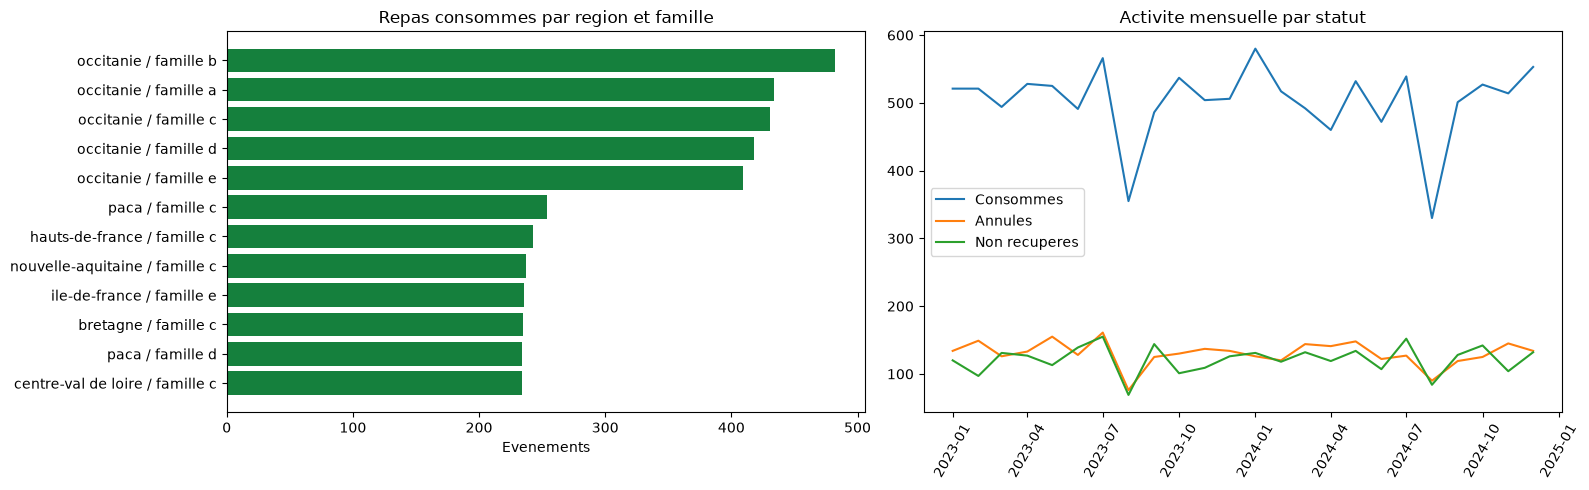

Graphique enregistre : C:\Users\loicn\Desktop\TP manipulation de données\reports\figures\cantine_activite.png


In [6]:
monthly_plot = monthly_activity.copy()
monthly_plot["periode"] = pd.to_datetime(monthly_plot.annee.astype(str) + "-" + monthly_plot.mois.astype(str).str.zfill(2))
site_plot = activity_by_region_family.head(12).copy()
site_plot["region_famille"] = site_plot.region.fillna("non appariee") + " / " + site_plot.famille.fillna("non appariee")
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].barh(site_plot.region_famille.iloc[::-1], site_plot.repas_consommes.iloc[::-1], color="#15803d")
axes[0].set_title("Repas consommes par region et famille")
axes[0].set_xlabel("Evenements")
axes[1].plot(monthly_plot.periode, monthly_plot.repas_consommes, label="Consommes")
axes[1].plot(monthly_plot.periode, monthly_plot.annules, label="Annules")
axes[1].plot(monthly_plot.periode, monthly_plot.non_recuperes, label="Non recuperes")
axes[1].set_title("Activite mensuelle par statut")
axes[1].tick_params(axis="x", rotation=60)
axes[1].legend()
fig.tight_layout()
figure_path = FIGURES_DIR / "cantine_activite.png"
fig.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()
print("Graphique enregistre :", figure_path)

## 5. Composant PySpark

Le module `src/canteen_pipeline.py` reproduit le nettoyage et les jointures sur Spark. PySpark n'est pas installe dans l'environnement local du notebook ; les cellules Pandas restent executables. Pour Spark, utiliser l'image Docker du projet.

In [7]:
if importlib.util.find_spec("pyspark") is None:
    spark_measurement = "Non execute localement : PySpark absent. Apres demarrage de Docker Desktop : docker compose up -d puis docker compose exec pyspark spark-submit src/canteen_pipeline.py"
    print(spark_measurement)
else:
    from canteen_pipeline import create_spark_session, build_canteen_dataframe
    import psutil
    spark = create_spark_session("PMD-groupe-03-cantine")
    spark.sparkContext.setLogLevel("ERROR")
    try:
        memory_before_mb = psutil.Process().memory_info().rss / 1024**2
        start = time.perf_counter()
        spark_df = build_canteen_dataframe(spark, GROUP_DIR)
        spark_count = spark_df.count()
        elapsed = time.perf_counter() - start
        memory_after_mb = psutil.Process().memory_info().rss / 1024**2
        print(f"{spark_count:,} lignes en {elapsed:.2f} s; RSS Python {memory_before_mb:.1f} -> {memory_after_mb:.1f} Mo (hors JVM).")
    finally:
        spark.stop()

Non execute localement : PySpark absent. Apres demarrage de Docker Desktop : docker compose up -d puis docker compose exec pyspark spark-submit src/canteen_pipeline.py


## 6. Controle du rendu

Les seuls champs a personnaliser sont les noms des membres et la date de soutenance.

In [8]:
checks = {
    "Sources cantine presentes": all(path.exists() for path in paths.values()),
    "Pipeline PySpark present": (ROOT / "src" / "canteen_pipeline.py").exists(),
    "Jeu nettoye Parquet produit": OUTPUT_PARQUET.exists(),
    "Tableaux CSV produits": (PROCESSED_DIR / "cantine_par_region_famille.csv").exists() and (PROCESSED_DIR / "cantine_par_mois.csv").exists(),
    "Graphique PNG produit": figure_path.exists(),
    "Artefacts versionnables presents": all((ARTIFACTS_DIR / name).exists() for name in ["cantine_projet_pandas.parquet", "cantine_par_region_famille.csv", "cantine_par_mois.csv"]),
    "Note methodologique presente": (ROOT / "note_methodologique.md").exists(),
    "Support de soutenance present": (ROOT / "soutenance.md").exists(),
}
for label, ok in checks.items():
    print(f"{'OK' if ok else 'MANQUANT':<10} {label}")
if not all(checks.values()):
    raise RuntimeError("Le controle du livrable a echoue.")
print("\nLivrable technique complet. Ajouter les noms et la date avant depot.")

OK         Sources cantine presentes
OK         Pipeline PySpark present
OK         Jeu nettoye Parquet produit
OK         Tableaux CSV produits
OK         Graphique PNG produit
OK         Artefacts versionnables presents
OK         Note methodologique presente
OK         Support de soutenance present

Livrable technique complet. Ajouter les noms et la date avant depot.


## 7. Limites et preparation aux questions

- Les donnees synthetiques ne decrivent pas une cantine reelle.
- Les statuts refleteront les enregistrements sources, pas necessairement une realisation physique verifiee.
- Le cout est conserve a la granularite declaree dans la table ; il n'est pas multiplie par les portions.
- Les grammages absents restent inconnus et sont exclus des moyennes correspondantes.
- Les quantites atypiques sont conservees car aucun seuil metier n'a ete confirme.
- L'execution Spark locale ne prouve pas un gain de vitesse pour ce volume.

**Questions probables :** les doublons exacts sont retires, mais un id repete divergent devrait etre analyse avant suppression ; les statuts sont normalises pour eviter les fausses categories ; les dates manquantes sont exclues des analyses temporelles apres comptage ; les couts declares ne sont pas extrapoles.